# Daily Data Task #1 -- 11/5
(Federal Reserve Bank of St. Louis): monthly US unemployment rate and CPI
Tool: Stata by default — swap to R/Python if you prefer
Time: aim for ~45 minutes
Your task:
1. Import both CSVs; rename the value columns to unrate and cpi, and parse observation_date into a monthly date variable.
2. Merge 1:1 on the monthly date. Tabulate the merge result: how many months matched, how many are unmatched from each file, and explain why.
3. Generate year-over-year inflation (12-month percent change in cpi) and scatter unrate against inflation, coloring 1948-2019 and 2020 onward differently. Describe the relationship in each period.
Expected output: the merge tabulation, one scatter figure, and 3-4 sentences on the pattern and what it does not establish.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
cpi = pd.read_csv("data/CPIAUCSL.csv")
unrate = pd.read_csv("data/UNRATE.csv")

In [3]:
print(cpi.head())
print(unrate.head())

  observation_date  CPIAUCSL
0       1947-01-01     21.48
1       1947-02-01     21.62
2       1947-03-01     22.00
3       1947-04-01     22.00
4       1947-05-01     21.95
  observation_date  UNRATE
0       1948-01-01     3.4
1       1948-02-01     3.8
2       1948-03-01     4.0
3       1948-04-01     3.9
4       1948-05-01     3.5


In [4]:
cpi = cpi.rename(columns={'DATE': 'date', 'CPIAUCSL': 'cpi'})
unrate = unrate.rename(columns={'DATE': 'date', 'UNRATE': 'unrate'})

In [5]:
df = pd.merge(cpi, unrate, on='observation_date', how='outer', indicator=True)
print(df['_merge'].value_counts())

df = pd.merge(cpi, unrate, on='observation_date', how='inner', indicator=True)

_merge
both          945
left_only      12
right_only      0
Name: count, dtype: int64


1 year of data is unmatched. The CPI measure is captured for the entire horizon that unemployment rate is retreived for, with the exception of the year 1947. Data in this year is only available for CPI

In [6]:
df['observation_date'] = pd.to_datetime(df['observation_date'])

In [7]:
df["inf_rate"] = df['cpi'].pct_change(periods=12)

In [8]:
df.head(20)

,observation_date,cpi,unrate,_merge,inf_rate
0,1948-01-01,23.68,3.4,both,NaN
1,1948-02-01,23.67,3.8,both,NaN
2,1948-03-01,23.50,4.0,both,NaN
3,1948-04-01,23.82,3.9,both,NaN
4,1948-05-01,24.01,3.5,both,NaN
5,1948-06-01,24.15,3.6,both,NaN
6,1948-07-01,24.40,3.6,both,NaN
7,1948-08-01,24.43,3.9,both,NaN
8,1948-09-01,24.36,3.8,both,NaN
9,1948-10-01,24.31,3.7,both,NaN


In [9]:
df['year'] = df['observation_date'].dt.year

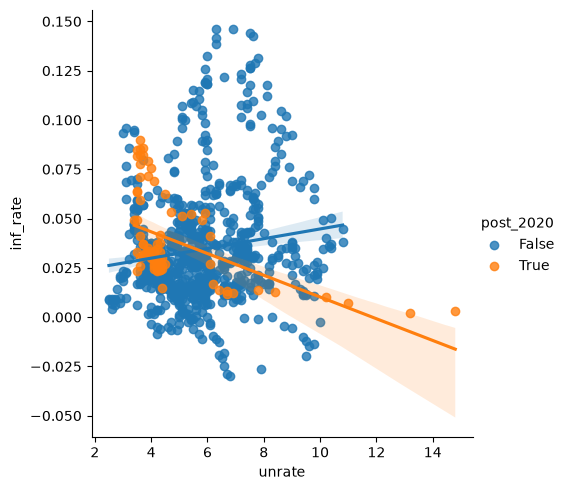

In [10]:
sns.lmplot(
    data=df.assign(post_2020 = df["year"] > 2019), 
    x="unrate", 
    y="inf_rate", 
    hue="post_2020"
)


## Patterns
- Based on the plot, there is evidence of a change in 